# Phase 6 — Class Imbalance, Threshold Optimization, Calibration and Final Model Evaluation

This notebook locks the Phase 5 Random Forest architecture, evaluates training-only calibration alternatives, selects a reproducible operating threshold under a 20% contact-capacity assumption, and then performs one final evaluation on the previously sealed test partition.

The notebook does **not** perform explainability, customer-level reporting, retention simulation, or causal impact analysis.

## 1. Introduction

Phase 5 selected a tuned Random Forest using five-fold training-only cross-validation. Phase 6 converts that provisional ranking model into a locked probability-producing artifact and evaluates it once on the final held-out data.

## 2. Business evaluation objective

The retention team can contact at most 20% of customers. We therefore need both reliable risk ordering and a clear operating policy. A fixed probability threshold is evaluated for repeatable classification, while the future campaign's strict top-k capacity rule remains conceptually separate. Predicting churn does not prove that an intervention will prevent it.

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.metrics import classification_report

CURRENT = Path.cwd().resolve()
ROOT = CURRENT.parent if CURRENT.name == 'notebooks' else CURRENT
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.evaluation import (
    DEFAULT_CONTACT_CAPACITY, build_probability_estimator,
    calibration_diagnostics, choose_calibration_method,
    compute_classification_metrics, compute_threshold_metrics, curve_data,
    generate_nested_calibration_oof, positive_class_probabilities,
    predictions_at_threshold, robustness_summary, save_json,
    select_operating_threshold, summarize_calibration_methods,
)
from src.feature_engineering import ENGINEERED_NUMERICAL_FEATURES
from src.modeling import RANDOM_STATE, build_model_pipelines, make_cv_splits
from src.preprocessing import (
    CATEGORICAL_FEATURES, IDENTIFIER_COLUMN, NUMERICAL_FEATURES, TARGET_COLUMN,
    apply_deterministic_cleaning, dataframe_fingerprint, load_and_validate_data,
    separate_features_target_ids,
)

RAW_PATH = ROOT / 'data' / 'raw' / 'customer_churn_advanced_dataset.csv'
CLEANED_PATH = ROOT / 'data' / 'processed' / '02_cleaned_dataset.csv'
SPLIT_PATH = ROOT / 'data' / 'processed' / '02_split_indices.json'
PHASE5_METADATA_PATH = ROOT / 'reports' / 'modeling' / 'phase5_model_metadata.json'
PHASE5_OOF_PATH = ROOT / 'data' / 'processed' / '05_selected_model_oof_probabilities.csv'
PHASE5_FOLD_PATH = ROOT / 'reports' / 'modeling' / 'phase5_fold_results.csv'
PHASE5_WEIGHT_PATH = ROOT / 'reports' / 'modeling' / 'phase5_class_weight_comparison.csv'
PHASE5_CANDIDATE_PATH = ROOT / 'models' / 'phase5_candidate_model.joblib'

EVALUATION_DIR = ROOT / 'reports' / 'evaluation'
FIGURE_DIR = ROOT / 'reports' / 'figures'
FINAL_MODEL_PATH = ROOT / 'models' / '03_model_artifact.joblib'
FINAL_METADATA_PATH = ROOT / 'models' / 'final_model_metadata.json'
LOCK_PATH = EVALUATION_DIR / 'phase6_locked_policy.json'
EVALUATION_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
FINAL_MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

BLUE = '#3569D4'
PURPLE = '#8051D6'
LIGHT_BLUE = '#8CB4F5'
LIGHT_PURPLE = '#B9A2EA'
sns.set_theme(style='whitegrid', context='talk')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def index_hash(values):
    payload = json.dumps([int(value) for value in values], separators=(',', ':'))
    return hashlib.sha256(payload.encode('utf-8')).hexdigest()

def save_figure(fig, filename):
    fig.tight_layout()
    path = FIGURE_DIR / filename
    fig.savefig(path, dpi=160, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'Saved: {path.relative_to(ROOT)}')

print(f'Python: {sys.version.split()[0]}; scikit-learn: {sklearn.__version__}')

Python: 3.13.3; scikit-learn: 1.9.1


## 3. Selected model overview

The selected architecture must match the measured Phase 5 decision rather than being replaced after seeing final-test outcomes. The expected model is a tuned Random Forest with balanced class weights, embedded after the Phase 4 feature-engineering and preprocessing steps.

In [2]:
required_paths = (
    RAW_PATH, CLEANED_PATH, SPLIT_PATH, PHASE5_METADATA_PATH,
    PHASE5_OOF_PATH, PHASE5_FOLD_PATH, PHASE5_WEIGHT_PATH,
    PHASE5_CANDIDATE_PATH,
)
missing = [str(path) for path in required_paths if not path.is_file()]
if missing:
    raise FileNotFoundError(f'Missing Phase 6 prerequisites: {missing}')

raw_hash_before = sha256(RAW_PATH)
cleaned_hash_before = sha256(CLEANED_PATH)
split_hash_before = sha256(SPLIT_PATH)

phase5_metadata = json.loads(PHASE5_METADATA_PATH.read_text(encoding='utf-8'))
split = json.loads(SPLIT_PATH.read_text(encoding='utf-8'))
cleaned_df = apply_deterministic_cleaning(load_and_validate_data(CLEANED_PATH))

assert phase5_metadata['model_key'] == 'random_forest'
assert phase5_metadata['artifact_role'].startswith('provisional')
assert phase5_metadata['final_test_used'] is False
assert phase5_metadata['training_dataset_fingerprint'] == split['dataset_fingerprint']
assert dataframe_fingerprint(cleaned_df) == split['dataset_fingerprint']
assert split['target_mapping'] == {'0': 0, '1': 1}

train_indices = split['train_indices']
sealed_test_indices = split['test_indices']
assert len(train_indices) == 960 and len(sealed_test_indices) == 240
assert set(train_indices).isdisjoint(sealed_test_indices)

# Only the training rows are materialized before the policy lock.
train_df = cleaned_df.iloc[train_indices].copy()
X_train, y_train, train_customer_ids = separate_features_target_ids(train_df)
assert IDENTIFIER_COLUMN not in X_train and TARGET_COLUMN not in X_train

# joblib files must only be loaded from trusted sources. This is the locally
# generated Phase 5 artifact whose metadata and repository context were checked.
phase5_candidate = joblib.load(PHASE5_CANDIDATE_PATH)
assert list(phase5_candidate.named_steps) == ['feature_engineering', 'preprocessing', 'model']
assert type(phase5_candidate.named_steps['model']).__name__ == 'RandomForestClassifier'

base_pipeline = build_model_pipelines(include_dummy=False)['random_forest']
base_pipeline.set_params(**phase5_metadata['best_parameters'], model__n_jobs=1)
selected_parameters = {
    key: base_pipeline.get_params()[key]
    for key in phase5_metadata['best_parameters']
}
assert selected_parameters == phase5_metadata['best_parameters']

print(f"Selected model: {phase5_metadata['model_name']}")
print(f"Best parameters: {selected_parameters}")
print(f"Training rows available for policy development: {len(X_train):,}")
print(f"Sealed test rows recorded but not inspected: {len(sealed_test_indices):,}")

Selected model: Random Forest
Best parameters: {'model__class_weight': 'balanced', 'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 2, 'model__min_samples_split': 10, 'model__n_estimators': 400}
Training rows available for policy development: 960
Sealed test rows recorded but not inspected: 240


## 4. Train/test integrity verification

The saved Phase 2 split and order-sensitive dataset fingerprint are reused. Prior to policy locking, this notebook materializes only the training partition. Test indices can be checked for disjointness without inspecting their outcomes.

In [3]:
phase5_oof = pd.read_csv(PHASE5_OOF_PATH)
assert list(phase5_oof.columns) == [
    'dataset_row_index', 'cv_fold', 'oof_churn_probability'
]
assert len(phase5_oof) == len(X_train)
assert phase5_oof['dataset_row_index'].is_unique
assert set(phase5_oof['dataset_row_index']) == set(X_train.index)
assert phase5_oof['oof_churn_probability'].between(0, 1).all()

cv_splits = make_cv_splits(X_train, y_train)
for fold, (_, validation_positions) in enumerate(cv_splits, start=1):
    expected_indices = set(X_train.index.to_numpy()[validation_positions])
    saved_indices = set(phase5_oof.loc[phase5_oof['cv_fold'] == fold, 'dataset_row_index'])
    assert expected_indices == saved_indices

integrity = pd.DataFrame({
    'check': [
        'dataset fingerprint', 'training rows', 'sealed test rows',
        'row overlap', 'OOF row coverage', 'target mapping',
    ],
    'value': [
        split['dataset_fingerprint'], len(train_indices), len(sealed_test_indices),
        len(set(train_indices) & set(sealed_test_indices)),
        phase5_oof['dataset_row_index'].nunique(), '0=retained, 1=churned',
    ],
})
display(integrity)

,check,value
0,dataset fingerprint,df788deba598b73abdc3a41b8a1947af63a90c5f369c2a...
1,training rows,960
2,sealed test rows,240
3,row overlap,0
4,OOF row coverage,960
5,target mapping,"0=retained, 1=churned"


## 5. Target class imbalance

Accuracy alone is misleading when one class dominates. Here churn is the majority class, so a classifier predicting churn for everyone would appear accurate but would not rank risk or protect scarce contact capacity. Phase 5 showed that balanced weighting improved the selected Random Forest's ranking metrics, so that already-selected treatment is retained; SMOTE is neither necessary nor introduced.

In [4]:
class_counts = y_train.value_counts().sort_index()
retained_count = int(class_counts.loc[0])
churn_count = int(class_counts.loc[1])
imbalance_summary = pd.DataFrame({
    'measure': [
        'retained customers', 'churned customers', 'non-churn percentage',
        'churn percentage', 'majority-to-minority ratio',
    ],
    'value': [
        retained_count, churn_count, retained_count / len(y_train),
        churn_count / len(y_train), churn_count / retained_count,
    ],
})
display(imbalance_summary)

weight_results = pd.read_csv(PHASE5_WEIGHT_PATH)
display(weight_results.loc[
    weight_results['model_key'] == 'random_forest',
    ['model', 'class_weight', 'mean_precision', 'mean_recall', 'mean_f1',
     'mean_roc_auc', 'mean_pr_auc'],
].fillna('None'))

,measure,value
0,retained customers,131.0000
1,churned customers,829.0000
2,non-churn percentage,0.1365
3,churn percentage,0.8635
4,majority-to-minority ratio,6.3282


,model,class_weight,mean_precision,mean_recall,mean_f1,mean_roc_auc,mean_pr_auc
2,Random Forest,None,0.8837,0.9891,0.9334,0.8575,0.9706
3,Random Forest,balanced,0.9193,0.9433,0.9309,0.8701,0.9732


## 6. Evaluation metrics

- **Accuracy** is the fraction of correct classifications, but it can look strong under imbalance.
- **Precision** asks: among customers predicted to churn, how many actually churned?
- **Recall** asks: among actual churners, how many were identified?
- **F1** balances precision and recall at one threshold.
- **ROC-AUC** evaluates discrimination across thresholds.
- **Average Precision (AP)** summarizes the precision-recall ranking without trapezoidal interpolation. It is interpreted relative to the 86.35% churn prevalence.
- **Brier score** and **log loss** assess probability quality; lower is better.
- The **confusion matrix** exposes the counts behind threshold-dependent metrics.

Undefined precision is consistently set to zero when no customer is predicted positive.

## 7. Threshold analysis

The default 0.50 threshold is only a reference. We first examine the Phase 5 uncalibrated OOF probabilities across a fine grid and at the requested 0.10 increments. These are out-of-fold training predictions: each row was scored by a model that did not fit that row.

,threshold,predicted_positive_count,predicted_positive_rate,precision,recall,f1,false_positive,false_negative,true_positive,true_negative
0,0.1000,953,0.9927,0.8699,1.0000,0.9304,124,0,829,7
1,0.2000,918,0.9563,0.8900,0.9855,0.9353,101,12,817,30
2,0.3000,873,0.9094,0.9084,0.9566,0.9318,80,36,793,51
3,0.4000,830,0.8646,0.9253,0.9264,0.9259,62,61,768,69
4,0.5000,757,0.7885,0.9445,0.8625,0.9016,42,114,715,89
5,0.6000,689,0.7177,0.9623,0.7998,0.8735,26,166,663,105
6,0.7000,625,0.6510,0.9744,0.7346,0.8377,16,220,609,115
7,0.8000,539,0.5615,0.9852,0.6405,0.7763,8,298,531,123
8,0.9000,405,0.4219,0.9901,0.4837,0.6499,4,428,401,127


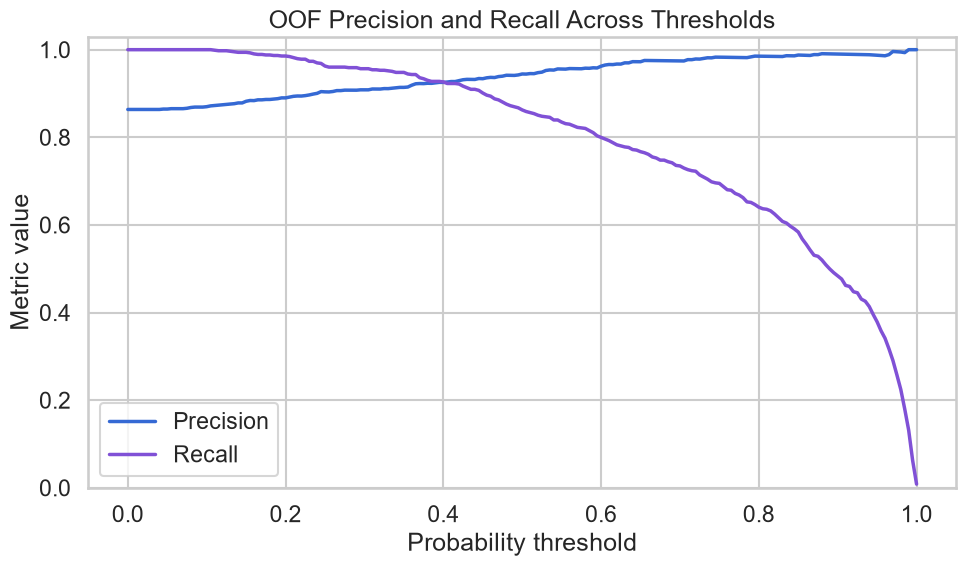

Saved: reports\figures\phase6_threshold_precision_recall.png


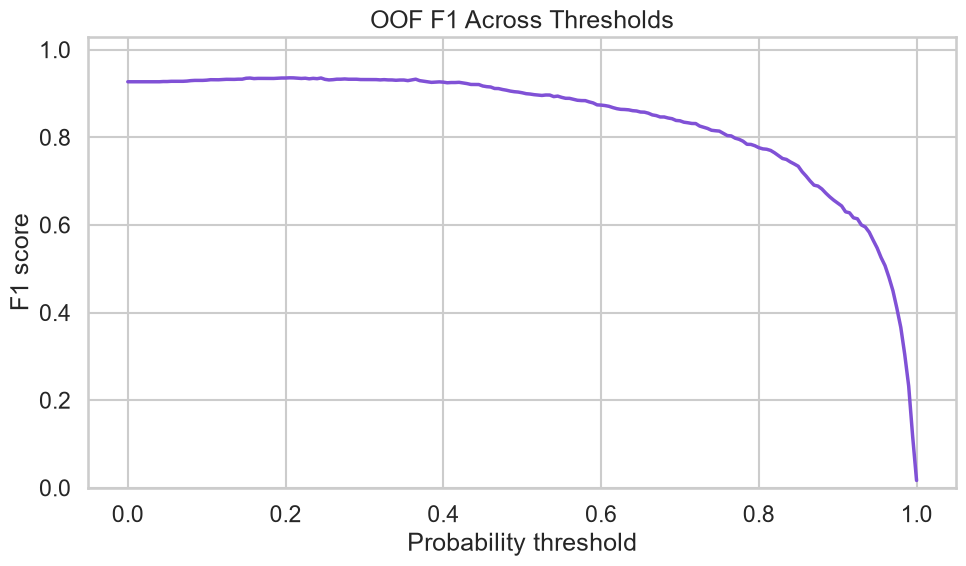

Saved: reports\figures\phase6_threshold_f1.png


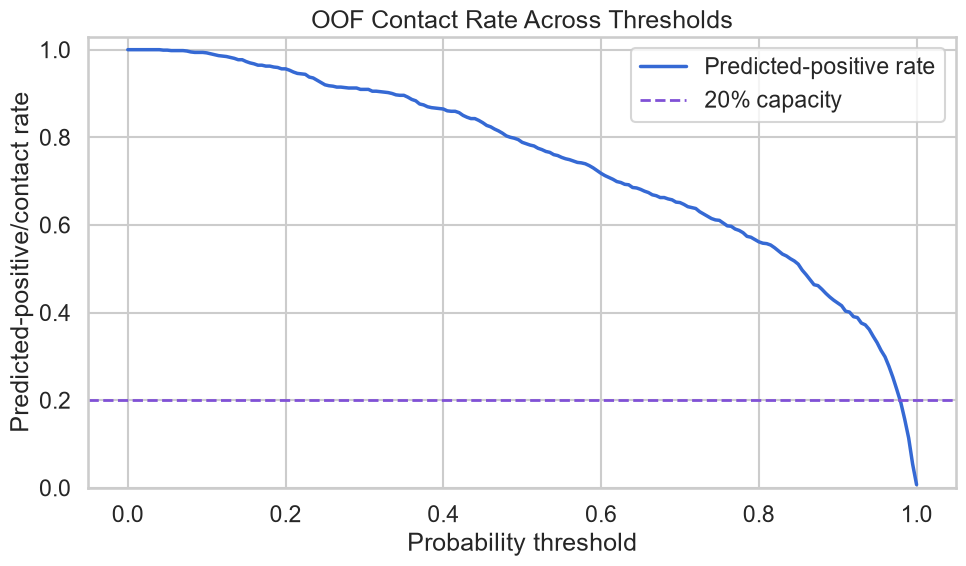

Saved: reports\figures\phase6_contact_rate_threshold.png


In [5]:
phase5_oof_aligned = phase5_oof.set_index('dataset_row_index').loc[X_train.index]
uncalibrated_oof_probability = phase5_oof_aligned['oof_churn_probability'].to_numpy()

fine_thresholds = np.linspace(0.0, 1.0, 201)
uncalibrated_threshold_grid = compute_threshold_metrics(
    y_train, uncalibrated_oof_probability, fine_thresholds
)
requested_thresholds = np.arange(0.1, 1.0, 0.1)
uncalibrated_key_thresholds = compute_threshold_metrics(
    y_train, uncalibrated_oof_probability, requested_thresholds
)
display(uncalibrated_key_thresholds)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(uncalibrated_threshold_grid['threshold'], uncalibrated_threshold_grid['precision'], color=BLUE, linewidth=2.5, label='Precision')
ax.plot(uncalibrated_threshold_grid['threshold'], uncalibrated_threshold_grid['recall'], color=PURPLE, linewidth=2.5, label='Recall')
ax.set(title='OOF Precision and Recall Across Thresholds', xlabel='Probability threshold', ylabel='Metric value', ylim=(0, 1.03))
ax.legend()
save_figure(fig, 'phase6_threshold_precision_recall.png')

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(uncalibrated_threshold_grid['threshold'], uncalibrated_threshold_grid['f1'], color=PURPLE, linewidth=2.5)
ax.set(title='OOF F1 Across Thresholds', xlabel='Probability threshold', ylabel='F1 score', ylim=(0, 1.03))
save_figure(fig, 'phase6_threshold_f1.png')

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(uncalibrated_threshold_grid['threshold'], uncalibrated_threshold_grid['predicted_positive_rate'], color=BLUE, linewidth=2.5, label='Predicted-positive rate')
ax.axhline(DEFAULT_CONTACT_CAPACITY, color=PURPLE, linestyle='--', linewidth=2, label='20% capacity')
ax.set(title='OOF Contact Rate Across Thresholds', xlabel='Probability threshold', ylabel='Predicted-positive/contact rate', ylim=(0, 1.03))
ax.legend()
save_figure(fig, 'phase6_contact_rate_threshold.png')

## 8. Business operating threshold selection

The prespecified rule maximizes OOF recall while requiring predicted-positive rate to remain at or below 20%. Ties are kept together: all scores equal to the threshold are included, and a tied group that would breach capacity is excluded. Precision, fewer contacts, and the higher threshold break any remaining ties.

This initial result uses uncalibrated probabilities. If calibration is adopted, the exact threshold is recomputed from the selected calibrated OOF probabilities before locking the policy.

In [6]:
uncalibrated_threshold_selection = select_operating_threshold(
    y_train, uncalibrated_oof_probability, capacity=DEFAULT_CONTACT_CAPACITY
)
display(pd.Series(uncalibrated_threshold_selection, name='uncalibrated OOF policy'))

threshold                                                              0.9797
predicted_positive_count                                             192.0000
predicted_positive_rate                                                0.2000
precision                                                              0.9948
recall                                                                 0.2304
f1                                                                     0.3741
false_positive                                                         1.0000
false_negative                                                       638.0000
true_positive                                                        191.0000
true_negative                                                        130.0000
capacity                                                               0.2000
selection_method            maximize OOF recall subject to contact rate <=...
tie_handling                probability >= threshold; all exact-

## 9. Probability calibration

A model can rank correctly while reporting biased probability levels. We compare uncalibrated, sigmoid, and isotonic probabilities using nested training-only validation. Each outer validation row is predicted by an estimator fitted without that row; sigmoid and isotonic calibrators are fitted through three inner stratified folds of the outer training data.

Ten equal-frequency bins are used where score variation permits. Bin counts are reported because calibration rates are uncertain in small bins.

In [7]:
calibration_oof = generate_nested_calibration_oof(
    base_pipeline,
    X_train,
    y_train,
    cv_splits,
    methods=('uncalibrated', 'sigmoid', 'isotonic'),
    inner_splits=3,
)
calibration_comparison, reliability_tables = summarize_calibration_methods(
    y_train, calibration_oof, n_bins=10
)
calibration_comparison.to_csv(
    EVALUATION_DIR / 'phase6_calibration_comparison.csv', index=False
)
for method, table in reliability_tables.items():
    table.to_csv(EVALUATION_DIR / f'phase6_calibration_bins_{method}.csv', index=False)

# Confirm that the nested workflow reproduces the Phase 5 uncalibrated OOF scores.
nested_uncalibrated = (
    calibration_oof.loc[calibration_oof['method'] == 'uncalibrated']
    .set_index('dataset_row_index').loc[X_train.index, 'probability'].to_numpy()
)
np.testing.assert_allclose(
    nested_uncalibrated, uncalibrated_oof_probability, rtol=0, atol=1e-12
)
display(calibration_comparison)
for method, table in reliability_tables.items():
    print(f'Calibration bins: {method}')
    display(table)

,method,observations,bins,prevalence,mean_predicted_probability,brier_score,log_loss,roc_auc,average_precision,expected_calibration_error
0,uncalibrated,960,10,0.8635,0.7457,0.1061,0.3328,0.8804,0.9773,0.1181
1,sigmoid,960,10,0.8635,0.8624,0.0840,0.2752,0.8818,0.9782,0.0219
2,isotonic,960,9,0.8635,0.8626,0.0845,0.3078,0.8718,0.9736,0.0129


Calibration bins: uncalibrated


,bin_number,sample_count,mean_predicted_probability,observed_churn_rate,probability_min,probability_max,absolute_gap
0,1,96,0.2002,0.4271,0.0443,0.3342,0.2269
1,2,96,0.4184,0.6771,0.3383,0.4835,0.2587
2,3,96,0.5566,0.7604,0.4876,0.6165,0.2039
3,4,96,0.6949,0.8750,0.6191,0.7584,0.1801
4,5,96,0.8124,0.9583,0.7588,0.8530,0.1460
5,6,96,0.8819,0.9792,0.8541,0.9157,0.0972
6,7,96,0.9416,1.0000,0.9158,0.9591,0.0584
7,8,96,0.9701,0.9688,0.9595,0.9797,0.0014
8,9,96,0.9858,0.9896,0.9797,0.9908,0.0038
9,10,96,0.9955,1.0000,0.9910,1.0000,0.0045


Calibration bins: sigmoid


,bin_number,sample_count,mean_predicted_probability,observed_churn_rate,probability_min,probability_max,absolute_gap
0,1,96,0.4686,0.4271,0.2695,0.6044,0.0415
1,2,96,0.6914,0.6667,0.6056,0.7596,0.0247
2,3,96,0.8082,0.7917,0.7649,0.8453,0.0165
3,4,96,0.8856,0.8646,0.8461,0.9183,0.0211
4,5,96,0.9349,0.9375,0.9189,0.9476,0.0026
5,6,96,0.9548,0.9896,0.9476,0.9611,0.0348
6,7,96,0.9653,0.9896,0.9611,0.9680,0.0243
7,8,96,0.9694,0.9792,0.9681,0.9707,0.0098
8,9,96,0.9717,0.9896,0.9707,0.9729,0.0178
9,10,96,0.9744,1.0000,0.9729,0.9768,0.0256


Calibration bins: isotonic


,bin_number,sample_count,mean_predicted_probability,observed_churn_rate,probability_min,probability_max,absolute_gap
0,1,96,0.4388,0.4375,0.0034,0.5890,0.0013
1,2,96,0.6715,0.6562,0.5922,0.7383,0.0152
2,3,96,0.7802,0.7708,0.7391,0.8300,0.0093
3,4,102,0.8749,0.8824,0.8345,0.9060,0.0074
4,5,90,0.9343,0.9889,0.9145,0.9534,0.0546
5,6,101,0.9645,0.9604,0.9543,0.9736,0.0041
6,7,98,0.9798,0.9898,0.9744,0.9862,0.0100
7,8,100,0.9915,0.9700,0.9869,0.9929,0.0215
8,9,181,0.9984,0.9945,0.9938,1.0000,0.0040


### Calibration method decision

The decision rule was fixed before final-test access: adopt a calibration method only if it improves Brier score by at least 0.002, lowers log loss and expected calibration error, and reduces neither AP nor ROC-AUC by more than 0.002. Among eligible methods, choose the lowest Brier score. This protects ranking quality while requiring a meaningful probability-quality gain. Isotonic calibration is treated cautiously because its flexibility can overfit limited calibration samples.

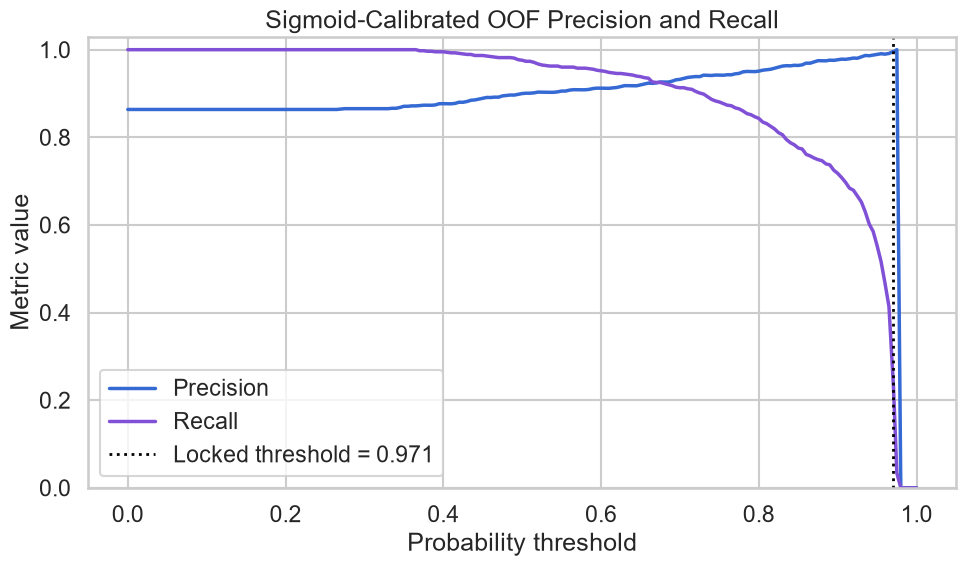

Saved: reports\figures\phase6_threshold_precision_recall.png


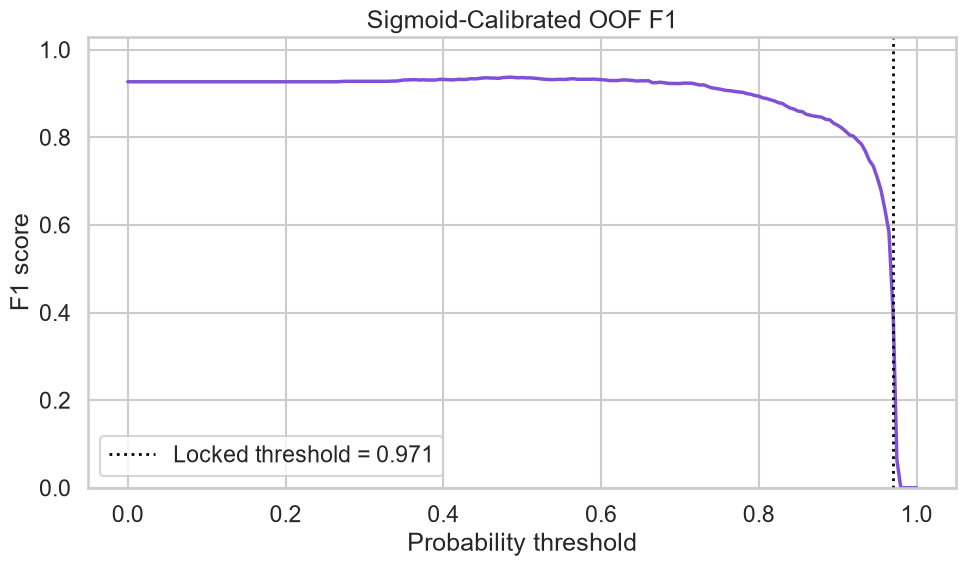

Saved: reports\figures\phase6_threshold_f1.png


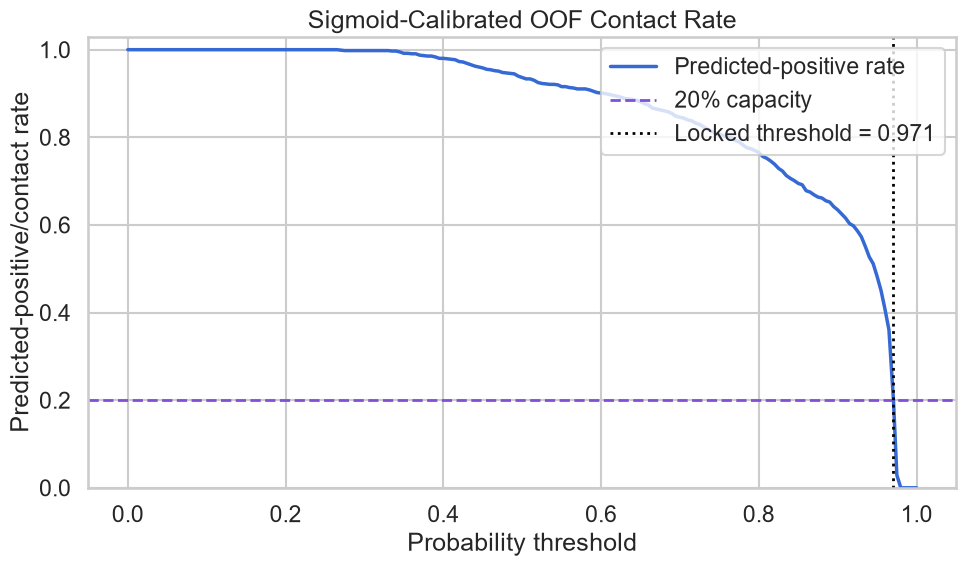

Saved: reports\figures\phase6_contact_rate_threshold.png
{'method': 'sigmoid', 'decision': 'adopt sigmoid calibration', 'rule': 'require Brier improvement >= 0.002, lower log loss and ECE, and AP/ROC-AUC degradation <= 0.002; choose lowest Brier score', 'brier_improvement': 0.022074619108786206}


threshold                                                              0.9707
predicted_positive_count                                             192.0000
predicted_positive_rate                                                0.2000
precision                                                              0.9948
recall                                                                 0.2304
f1                                                                     0.3741
false_positive                                                         1.0000
false_negative                                                       638.0000
true_positive                                                        191.0000
true_negative                                                        130.0000
capacity                                                               0.2000
selection_method            maximize OOF recall subject to contact rate <=...
tie_handling                probability >= threshold; all exact-

,threshold,predicted_positive_count,predicted_positive_rate,precision,recall,f1,false_positive,false_negative,true_positive,true_negative
0,0.1000,960,1.0000,0.8635,1.0000,0.9268,131,0,829,0
1,0.2000,960,1.0000,0.8635,1.0000,0.9268,131,0,829,0
2,0.3000,958,0.9979,0.8653,1.0000,0.9278,129,0,829,2
3,0.4000,941,0.9802,0.8767,0.9952,0.9322,116,4,825,15
4,0.5000,899,0.9365,0.8999,0.9759,0.9363,90,20,809,41
5,0.6000,865,0.9010,0.9121,0.9517,0.9315,76,40,789,55
6,0.7000,812,0.8458,0.9323,0.9131,0.9226,55,72,757,76
7,0.8000,735,0.7656,0.9510,0.8432,0.8939,36,130,699,95
8,0.9000,609,0.6344,0.9770,0.7177,0.8275,14,234,595,117
9,0.9707,192,0.2000,0.9948,0.2304,0.3741,1,638,191,130


In [8]:
calibration_decision = choose_calibration_method(calibration_comparison)
chosen_method = calibration_decision['method']
chosen_oof = (
    calibration_oof.loc[calibration_oof['method'] == chosen_method]
    .set_index('dataset_row_index').loc[X_train.index]
)
chosen_oof_probability = chosen_oof['probability'].to_numpy()

final_threshold_selection = select_operating_threshold(
    y_train, chosen_oof_probability, capacity=DEFAULT_CONTACT_CAPACITY
)
operating_threshold = float(final_threshold_selection['threshold'])

final_fine_thresholds = np.unique(
    np.concatenate([np.linspace(0.0, 1.0, 201), [operating_threshold]])
)
final_threshold_grid = compute_threshold_metrics(
    y_train, chosen_oof_probability, final_fine_thresholds
)
final_key_thresholds = compute_threshold_metrics(
    y_train,
    chosen_oof_probability,
    np.unique(np.concatenate([requested_thresholds, [0.5, operating_threshold]])),
)
final_threshold_grid.to_csv(EVALUATION_DIR / 'phase6_threshold_grid.csv', index=False)
final_key_thresholds.to_csv(EVALUATION_DIR / 'phase6_threshold_key_points.csv', index=False)
save_json(final_threshold_selection, EVALUATION_DIR / 'phase6_selected_threshold.json')

# Recreate the required threshold charts on the finally selected sigmoid scale.
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(final_threshold_grid['threshold'], final_threshold_grid['precision'], color=BLUE, linewidth=2.5, label='Precision')
ax.plot(final_threshold_grid['threshold'], final_threshold_grid['recall'], color=PURPLE, linewidth=2.5, label='Recall')
ax.axvline(operating_threshold, color='black', linestyle=':', linewidth=2, label=f'Locked threshold = {operating_threshold:.3f}')
ax.set(title='Sigmoid-Calibrated OOF Precision and Recall', xlabel='Probability threshold', ylabel='Metric value', ylim=(0, 1.03))
ax.legend(loc='lower left')
save_figure(fig, 'phase6_threshold_precision_recall.png')

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(final_threshold_grid['threshold'], final_threshold_grid['f1'], color=PURPLE, linewidth=2.5)
ax.axvline(operating_threshold, color='black', linestyle=':', linewidth=2, label=f'Locked threshold = {operating_threshold:.3f}')
ax.set(title='Sigmoid-Calibrated OOF F1', xlabel='Probability threshold', ylabel='F1 score', ylim=(0, 1.03))
ax.legend(loc='lower left')
save_figure(fig, 'phase6_threshold_f1.png')

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(final_threshold_grid['threshold'], final_threshold_grid['predicted_positive_rate'], color=BLUE, linewidth=2.5, label='Predicted-positive rate')
ax.axhline(DEFAULT_CONTACT_CAPACITY, color=PURPLE, linestyle='--', linewidth=2, label='20% capacity')
ax.axvline(operating_threshold, color='black', linestyle=':', linewidth=2, label=f'Locked threshold = {operating_threshold:.3f}')
ax.set(title='Sigmoid-Calibrated OOF Contact Rate', xlabel='Probability threshold', ylabel='Predicted-positive/contact rate', ylim=(0, 1.03))
ax.legend(loc='upper right')
save_figure(fig, 'phase6_contact_rate_threshold.png')

print(calibration_decision)
display(pd.Series(final_threshold_selection, name='locked training-only policy'))
display(final_key_thresholds)

## 10. Final held-out test evaluation

Before any test outcomes are materialized, the selected architecture, balanced class weighting, sigmoid/uncalibrated calibration decision, operating threshold, metric definitions, contact-capacity assumption, random seed, split identity, and software versions are persisted. The complete estimator is fitted using training rows only and serialized. The lock file is not changed after test evaluation.

In [9]:
final_estimator = build_probability_estimator(
    base_pipeline, chosen_method, calibration_splits=5
)
final_estimator.fit(X_train, y_train)
training_probe_before_save = positive_class_probabilities(
    final_estimator, X_train.iloc[:12]
)
joblib.dump(final_estimator, FINAL_MODEL_PATH)

# Load only the trusted artifact generated immediately above.
loaded_final_estimator = joblib.load(FINAL_MODEL_PATH)
training_probe_after_load = positive_class_probabilities(
    loaded_final_estimator, X_train.iloc[:12]
)
np.testing.assert_allclose(training_probe_before_save, training_probe_after_load)

unseen_probe = X_train.iloc[[0]].copy()
unseen_probe.loc[:, 'region'] = 'Future unseen region'
unseen_probability = positive_class_probabilities(loaded_final_estimator, unseen_probe)
assert 0 <= unseen_probability[0] <= 1

package_versions = {
    'python': sys.version.split()[0],
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'matplotlib': __import__('matplotlib').__version__,
    'seaborn': sns.__version__,
    'scikit_learn': sklearn.__version__,
    'joblib': joblib.__version__,
}
locked_policy = {
    'phase': 6,
    'policy_status': 'locked before final-test outcome access',
    'selected_model': phase5_metadata['model_name'],
    'model_key': phase5_metadata['model_key'],
    'hyperparameters': phase5_metadata['best_parameters'],
    'feature_engineering': list(ENGINEERED_NUMERICAL_FEATURES),
    'preprocessing': {
        'numerical_features': list(NUMERICAL_FEATURES) + list(ENGINEERED_NUMERICAL_FEATURES),
        'numerical_steps': ['median imputation', 'standard scaling'],
        'categorical_features': list(CATEGORICAL_FEATURES),
        'categorical_steps': ['constant Missing imputation', 'dense one-hot encoding'],
        'unknown_categories': 'ignored',
    },
    'class_weight': 'balanced',
    'calibration': {
        'method': chosen_method,
        'decision': calibration_decision,
        'comparison': calibration_comparison.to_dict(orient='records'),
        'selection_data': 'nested out-of-fold training predictions only',
        'inner_splits_for_comparison': 3,
        'folds_for_final_training_fit': 5,
    },
    'operating_threshold': operating_threshold,
    'threshold_selection': final_threshold_selection,
    'fixed_threshold_rule': 'predict churn when probability >= operating_threshold',
    'contact_capacity_assumption': DEFAULT_CONTACT_CAPACITY,
    'future_strict_capacity_policy': 'rank probabilities descending and select deterministic top-k; Phase 8 scope',
    'random_seed': RANDOM_STATE,
    'dataset_fingerprint': split['dataset_fingerprint'],
    'split_artifact_sha256': split_hash_before,
    'train_indices_sha256': index_hash(train_indices),
    'test_indices_sha256': index_hash(sealed_test_indices),
    'training_rows': len(train_indices),
    'test_rows': len(sealed_test_indices),
    'target_mapping': split['target_mapping'],
    'metrics_locked': [
        'accuracy', 'precision', 'recall', 'f1', 'roc_auc',
        'average_precision', 'brier_score', 'log_loss', 'confusion_matrix',
    ],
    'model_artifact': str(FINAL_MODEL_PATH.relative_to(ROOT)),
    'model_artifact_sha256': sha256(FINAL_MODEL_PATH),
    'trusted_artifact_warning': 'Load joblib artifacts only from trusted sources.',
    'package_versions': package_versions,
    'final_test_used_for_any_decision': False,
}
save_json(locked_policy, FINAL_METADATA_PATH)
save_json(locked_policy, LOCK_PATH)
metadata_hash_at_lock = sha256(FINAL_METADATA_PATH)
lock_hash_at_lock = sha256(LOCK_PATH)

print(f'Policy locked with threshold {operating_threshold:.12f}')
print(f'Calibration method: {chosen_method}')
print(f'Saved trusted local artifact: {FINAL_MODEL_PATH.relative_to(ROOT)}')
print(f'Saved locked metadata: {FINAL_METADATA_PATH.relative_to(ROOT)}')

Policy locked with threshold 0.970709000432
Calibration method: sigmoid
Saved trusted local artifact: models\03_model_artifact.joblib
Saved locked metadata: models\final_model_metadata.json


In [10]:
# First and only outcome evaluation block: materialize the sealed test rows now.
test_df = cleaned_df.iloc[sealed_test_indices].copy()
X_test, y_test, test_customer_ids = separate_features_target_ids(test_df)
assert IDENTIFIER_COLUMN not in X_test and TARGET_COLUMN not in X_test
assert set(train_customer_ids).isdisjoint(set(test_customer_ids))

test_probabilities = positive_class_probabilities(loaded_final_estimator, X_test)
selected_metrics = compute_classification_metrics(
    y_test, test_probabilities, threshold=operating_threshold
)
reference_metrics = compute_classification_metrics(
    y_test, test_probabilities, threshold=0.50
)

final_metrics_table = pd.DataFrame([
    {'policy': 'Preselected business threshold', **selected_metrics},
    {'policy': 'Reference threshold 0.50', **reference_metrics},
])
final_metrics_table.to_csv(EVALUATION_DIR / 'phase6_final_test_metrics.csv', index=False)
save_json(
    {
        'selected_business_threshold': selected_metrics,
        'reference_threshold_0_50': reference_metrics,
        'policy_was_locked_before_test': True,
    },
    EVALUATION_DIR / 'phase6_final_test_metrics.json',
)

test_predictions = predictions_at_threshold(test_probabilities, operating_threshold)
report = pd.DataFrame(
    classification_report(
        y_test, test_predictions, labels=[0, 1], target_names=['retained', 'churned'],
        output_dict=True, zero_division=0,
    )
).T
report.to_csv(EVALUATION_DIR / 'phase6_classification_report.csv')

confusion = pd.DataFrame(
    [[selected_metrics['true_negative'], selected_metrics['false_positive']],
     [selected_metrics['false_negative'], selected_metrics['true_positive']]],
    index=['Actual retained', 'Actual churned'],
    columns=['Predicted retained', 'Predicted churned'],
)
confusion.to_csv(EVALUATION_DIR / 'phase6_confusion_matrix.csv')

display(final_metrics_table[[
    'policy', 'threshold', 'predicted_positive_count', 'predicted_positive_rate',
    'accuracy', 'precision', 'recall', 'f1', 'roc_auc',
    'average_precision', 'brier_score', 'log_loss',
]])
display(report)
display(confusion)

,policy,threshold,predicted_positive_count,predicted_positive_rate,accuracy,precision,recall,f1,roc_auc,average_precision,brier_score,log_loss
0,Preselected business threshold,0.9707,99,0.4125,0.5417,0.9899,0.4734,0.6405,0.8994,0.9819,0.0825,0.2627
1,Reference threshold 0.50,0.5000,225,0.9375,0.8667,0.8889,0.9662,0.9259,0.8994,0.9819,0.0825,0.2627


,precision,recall,f1-score,support
retained,0.2270,0.9697,0.3678,33.0000
churned,0.9899,0.4734,0.6405,207.0000
accuracy,0.5417,0.5417,0.5417,0.5417
macro avg,0.6084,0.7216,0.5042,240.0000
weighted avg,0.8850,0.5417,0.6030,240.0000


,Predicted retained,Predicted churned
Actual retained,32,1
Actual churned,109,98


## 11. Confusion matrix

A true positive is a correctly identified churner. A false positive consumes contact capacity on a customer who stayed. A false negative is a churner omitted by the fixed-threshold campaign, while a true negative is a correctly excluded retained customer. False negatives represent missed retention opportunities, but contacting all predicted churners is infeasible and intervention success is not guaranteed.

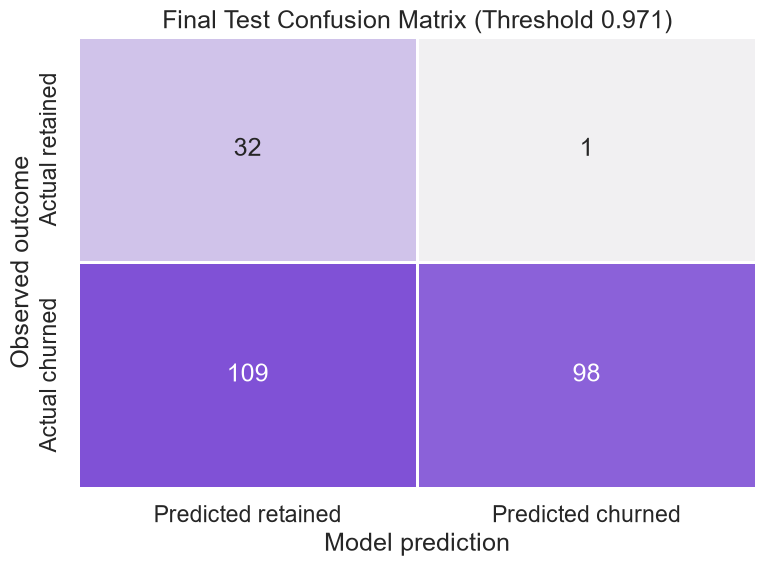

Saved: reports\figures\phase6_confusion_matrix.png


In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(confusion, annot=True, fmt='d', cmap=sns.light_palette(PURPLE, as_cmap=True), cbar=False, linewidths=1, ax=ax)
ax.set(title=f'Final Test Confusion Matrix (Threshold {operating_threshold:.3f})', xlabel='Model prediction', ylabel='Observed outcome')
save_figure(fig, 'phase6_confusion_matrix.png')

## 12. ROC curve

The held-out ROC curve measures ranking discrimination across all possible thresholds. It is reported once for generalization assessment and is not used to revise the locked model or threshold.

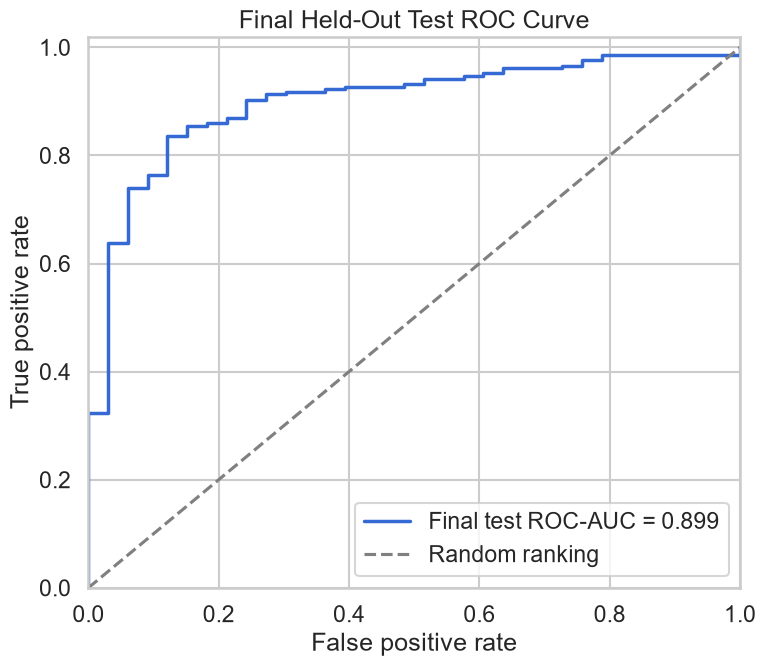

Saved: reports\figures\phase6_roc_curve.png


In [12]:
test_curves = curve_data(y_test, test_probabilities)
fig, ax = plt.subplots(figsize=(8, 7))
ax.plot(test_curves['fpr'], test_curves['tpr'], color=BLUE, linewidth=2.5, label=f"Final test ROC-AUC = {test_curves['roc_auc']:.3f}")
ax.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random ranking')
ax.set(title='Final Held-Out Test ROC Curve', xlabel='False positive rate', ylabel='True positive rate', xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc='lower right')
save_figure(fig, 'phase6_roc_curve.png')

## 13. Precision-recall curve

The precision-recall curve emphasizes positive-class ranking. Average Precision is compared with test churn prevalence; the prevalence line is the expected precision of a non-informative ranking, so a high AP must be interpreted in light of the already-high churn rate.

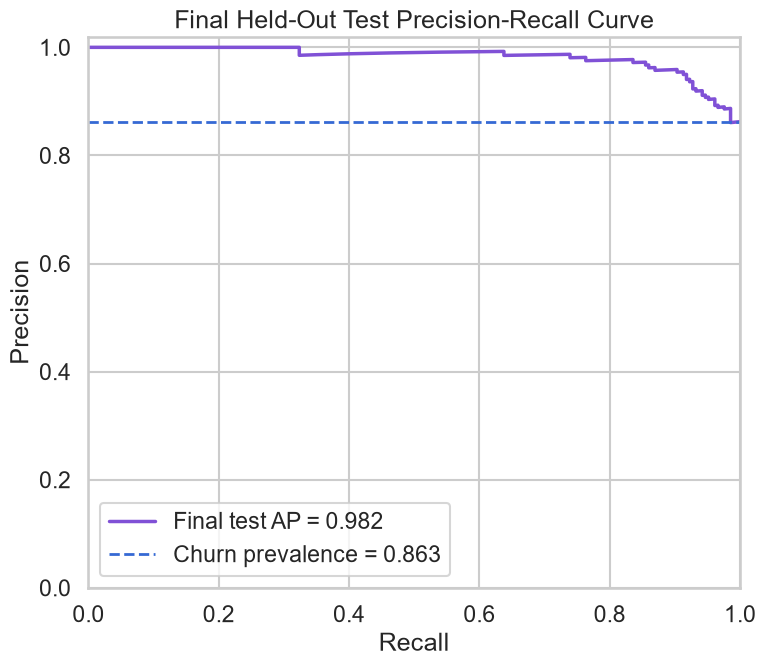

Saved: reports\figures\phase6_precision_recall_curve.png


In [13]:
fig, ax = plt.subplots(figsize=(8, 7))
ax.plot(test_curves['recall'], test_curves['precision'], color=PURPLE, linewidth=2.5, label=f"Final test AP = {test_curves['average_precision']:.3f}")
ax.axhline(test_curves['prevalence'], color=BLUE, linestyle='--', linewidth=2, label=f"Churn prevalence = {test_curves['prevalence']:.3f}")
ax.set(title='Final Held-Out Test Precision-Recall Curve', xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc='lower left')
save_figure(fig, 'phase6_precision_recall_curve.png')

## 14. Robustness analysis

Fold-to-fold variation from Phase 5 provides a training-only robustness check. Mean, sample standard deviation, minimum, and maximum summarize sensitivity to the validation fold. This is not independent external validation.

The final-test reliability curve is also shown descriptively. Its bins contain limited observations, so deviations should not be overinterpreted or used to retune the already-locked policy.

,metric,mean,standard_deviation,minimum,maximum,folds
0,precision,0.9451,0.0172,0.9268,0.9724,5
1,recall,0.8626,0.0340,0.8373,0.9212,5
2,roc_auc,0.8822,0.0229,0.8582,0.9096,5
3,pr_auc,0.9782,0.0060,0.9716,0.9855,5


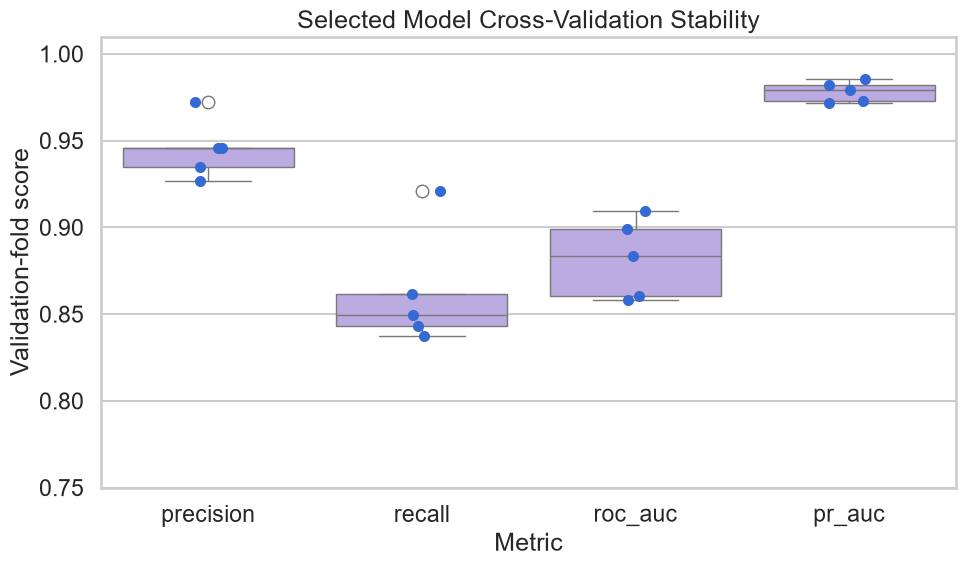

Saved: reports\figures\phase6_cv_stability.png


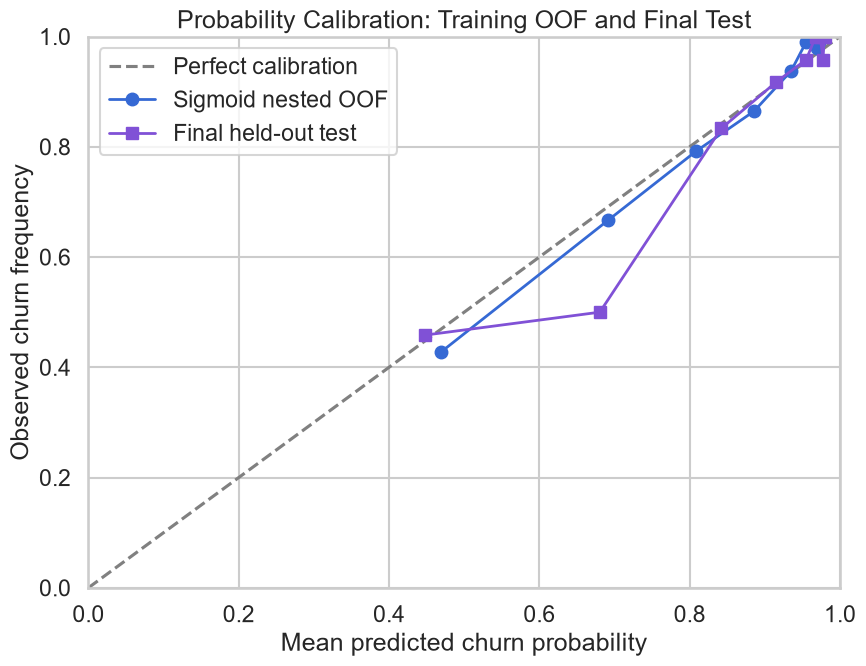

Saved: reports\figures\phase6_calibration_curve.png


In [14]:
phase5_folds = pd.read_csv(PHASE5_FOLD_PATH)
selected_folds = phase5_folds.loc[
    (phase5_folds['model_key'] == 'random_forest')
    & (phase5_folds['stage'] == 'Tuned')
].copy()
assert len(selected_folds) == 5
stability = robustness_summary(selected_folds)
stability.to_csv(EVALUATION_DIR / 'phase6_cv_robustness.csv', index=False)
display(stability)

stability_long = selected_folds.melt(
    id_vars='fold', value_vars=['precision', 'recall', 'roc_auc', 'pr_auc'],
    var_name='metric', value_name='score'
)
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=stability_long, x='metric', y='score', color=LIGHT_PURPLE, ax=ax)
sns.stripplot(data=stability_long, x='metric', y='score', color=BLUE, size=8, ax=ax)
ax.set(title='Selected Model Cross-Validation Stability', xlabel='Metric', ylabel='Validation-fold score', ylim=(0.75, 1.01))
save_figure(fig, 'phase6_cv_stability.png')

chosen_oof_summary, chosen_oof_bins = calibration_diagnostics(
    y_train, chosen_oof_probability, n_bins=10
)
test_calibration_summary, test_calibration_bins = calibration_diagnostics(
    y_test, test_probabilities, n_bins=10
)
test_calibration_bins.to_csv(
    EVALUATION_DIR / 'phase6_final_test_calibration_bins.csv', index=False
)
save_json(
    {'training_oof': chosen_oof_summary, 'final_test': test_calibration_summary},
    EVALUATION_DIR / 'phase6_probability_quality.json',
)

fig, ax = plt.subplots(figsize=(9, 7))
ax.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Perfect calibration')
ax.plot(chosen_oof_bins['mean_predicted_probability'], chosen_oof_bins['observed_churn_rate'], marker='o', color=BLUE, linewidth=2, label=f'{chosen_method.title()} nested OOF')
ax.plot(test_calibration_bins['mean_predicted_probability'], test_calibration_bins['observed_churn_rate'], marker='s', color=PURPLE, linewidth=2, label='Final held-out test')
ax.set(title='Probability Calibration: Training OOF and Final Test', xlabel='Mean predicted churn probability', ylabel='Observed churn frequency', xlim=(0, 1), ylim=(0, 1))
ax.legend(loc='upper left')
save_figure(fig, 'phase6_calibration_curve.png')

## 15. Model limitations

- The dataset is small, particularly the retained class, and one held-out split cannot establish performance across time or populations.
- Hyperparameters were selected before Phase 6 on the available training data; training OOF estimates may retain model-selection optimism.
- Calibration bins contain modest samples and isotonic calibration is especially vulnerable to overfitting.
- A fixed threshold does not guarantee an exact 20% future contact rate when the score distribution changes. Strict campaign capacity requires deterministic top-k ranking.
- Predictor timing and availability must be confirmed at the intended prediction date.
- Predictions are associational. They do not establish that a retention action will prevent churn.

## 16. Final evaluation summary

The final test is used only to measure the locked policy. Its results do not trigger model, calibration, feature, or threshold changes. Explainability is deferred to Phase 7, and intervention economics remain outside this phase.

**Execution note:** After the first successful final evaluation, the notebook was rerun once solely to remove overlapping calibration-bin annotations and to save the required threshold charts on the already-selected sigmoid probability scale. The model, calibration rule, threshold, split, and reported test results were not changed.

In [15]:
assert sum([
    selected_metrics['true_negative'], selected_metrics['false_positive'],
    selected_metrics['false_negative'], selected_metrics['true_positive'],
]) == len(y_test) == 240
assert sha256(FINAL_METADATA_PATH) == metadata_hash_at_lock
assert sha256(LOCK_PATH) == lock_hash_at_lock
assert sha256(RAW_PATH) == raw_hash_before
assert sha256(CLEANED_PATH) == cleaned_hash_before
assert sha256(SPLIT_PATH) == split_hash_before
assert np.isfinite(test_probabilities).all()
assert ((test_probabilities >= 0) & (test_probabilities <= 1)).all()
assert FINAL_MODEL_PATH.is_file() and FINAL_METADATA_PATH.is_file()

required_figures = [
    'phase6_threshold_precision_recall.png', 'phase6_threshold_f1.png',
    'phase6_contact_rate_threshold.png', 'phase6_confusion_matrix.png',
    'phase6_roc_curve.png', 'phase6_precision_recall_curve.png',
    'phase6_calibration_curve.png', 'phase6_cv_stability.png',
]
assert all((FIGURE_DIR / filename).is_file() for filename in required_figures)

execution_audit = {
    'phase': 6,
    'notebook_completed': True,
    'technical_rerun_count_after_first_success': 1,
    'technical_rerun_reason': 'cosmetic calibration-label cleanup and final calibrated-scale threshold charts; no policy change',
    'policy_locked_before_test': True,
    'lock_sha256': lock_hash_at_lock,
    'metadata_unchanged_after_test': sha256(FINAL_METADATA_PATH) == metadata_hash_at_lock,
    'selected_model_matches_phase5': True,
    'threshold_selected_from_training_oof_only': True,
    'calibration_selected_with_nested_training_cv_only': True,
    'final_test_rows': len(y_test),
    'confusion_matrix_total': int(confusion.to_numpy().sum()),
    'raw_dataset_unchanged': sha256(RAW_PATH) == raw_hash_before,
    'cleaned_dataset_unchanged': sha256(CLEANED_PATH) == cleaned_hash_before,
    'split_artifact_unchanged': sha256(SPLIT_PATH) == split_hash_before,
    'artifact_reload_probabilities_consistent': bool(
        np.allclose(training_probe_before_save, training_probe_after_load)
    ),
    'final_test_metrics': selected_metrics,
}
save_json(execution_audit, EVALUATION_DIR / 'phase6_execution_audit.json')

print('Phase 6 verification complete.')
print(f"Locked method/threshold: {chosen_method} / {operating_threshold:.12f}")
print(f"Final test ROC-AUC: {selected_metrics['roc_auc']:.4f}")
print(f"Final test Average Precision: {selected_metrics['average_precision']:.4f}")
print('No Phase 7 explainability or Phase 8 intervention simulation was performed.')

Phase 6 verification complete.
Locked method/threshold: sigmoid / 0.970709000432
Final test ROC-AUC: 0.8994
Final test Average Precision: 0.9819
No Phase 7 explainability or Phase 8 intervention simulation was performed.
